# SmartMovie — Analyse exploratoire des données (EDA)

Ce notebook charge les données **depuis MongoDB** (source de vérité, alimentée par le pipeline ETL) et produit les visualisations demandées avec Pandas, Matplotlib et Seaborn, accompagnées d'une courte interprétation pour chacune.

**Pourquoi MongoDB et pas `raw.json` ?**
`raw.json` est un fichier intermédiaire produit par l'étape d'extraction. Une fois les données upsertées dans MongoDB (avec `movie_id` en clé unique), c'est la base qui devient la source de vérité : dédupliquée, à jour, et interrogeable. C'est donc elle qu'on utilise pour l'analyse.


## 1. Imports & connexion à MongoDB

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
from dotenv import load_dotenv

load_dotenv()

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"


In [2]:
MONGO_URI = os.getenv("MONGO_URI")

client = MongoClient(MONGO_URI)
db = client["smartmovie"]
collection = db["movies"]

# On exclut le champ technique _id de Mongo, on n'en a pas besoin ici
cursor = collection.find({}, {"_id": 0})
df = pd.DataFrame(list(cursor))

print(f"{len(df)} films chargés depuis MongoDB")
df.head()


931 films chargés depuis MongoDB


,movie_id,budget,genres,keywords,original_language,overview,popularity,release_date,revenue,runtime,title,vote_average,vote_count
0,969681,225000000,"Science Fiction, Action, Adventure","mind control, new york city, hero, mutation, s...",en,Fighting crime full-time as Spider-Man in a wo...,687.7014,1785283200000,2495683000,145,Spider-Man: Brand New Day,7.865,2923
1,1423191,75000000,"Horror, Science Fiction, Adventure","outbreak, survival, zombie, based on video gam...",en,Medical courier Bryan unwittingly finds himsel...,407.7241,1789516800000,196476247,95,Resident Evil,7.300,556
2,1368337,250000000,"Adventure, Action, Fantasy","ship, trojan war, greek mythology, historical ...",en,"Odysseus, the legendary King of Ithaca, embark...",366.2926,1784073600000,1751248000,173,The Odyssey,8.019,3946
3,1751701,100000,"Science Fiction, Drama, Thriller","asteroid, loss, love, loneliness, disaster, de...",en,"After losing his father, Ethan Nichols inherit...",265.7821,1789430400000,0,95,After Impact,6.281,16
4,1084244,250000000,"Animation, Family, Comedy, Adventure","farm, island, pig, horse, rescue mission, riva...",en,When Bonnie receives a Lilypad tablet as a gif...,198.3883,1781654400000,1136476240,102,Toy Story 5,8.319,2389


## 2. Aperçu et nettoyage rapide

Avant de visualiser, on prépare les données :
- conversion de `release_date` en date, extraction de l'année ;
- les valeurs `0` dans `budget`, `revenue` et `runtime` sont très probablement des données manquantes (TMDB ne les fournit pas pour tous les films) plutôt que de vraies valeurs nulles — on les traite comme `NaN` pour ne pas fausser les statistiques ;
- `genres` et `keywords` sont des chaînes séparées par des virgules : on les explose en listes pour pouvoir compter par genre/mot-clé.


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 931 entries, 0 to 930
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   movie_id           931 non-null    int64  
 1   budget             931 non-null    int64  
 2   genres             931 non-null    str    
 3   keywords           931 non-null    str    
 4   original_language  931 non-null    str    
 5   overview           931 non-null    str    
 6   popularity         931 non-null    float64
 7   release_date       931 non-null    int64  
 8   revenue            931 non-null    int64  
 9   runtime            931 non-null    int64  
 10  title              931 non-null    str    
 11  vote_average       931 non-null    float64
 12  vote_count         931 non-null    int64  
dtypes: float64(2), int64(6), str(5)
memory usage: 565.6 KB


In [4]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
movie_id,931.0,NaN,NaN,NaN,520134.16971,539594.297268,11.0,10781.5,333339.0,1007745.5,1764193.0
budget,931.0,NaN,NaN,NaN,73480756.340494,79459931.396402,0.0,7500000.0,48000000.0,120000000.0,658800000.0
genres,931,416,Drama,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
keywords,931,887,,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_language,931,25,en,811,NaN,NaN,NaN,NaN,NaN,NaN,NaN
overview,931,929,,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,931.0,NaN,NaN,NaN,35.445363,43.055766,11.2236,19.2792,24.2286,34.3349,687.7014
release_date,931.0,NaN,NaN,NaN,1375079108055.854004,469814966124.488525,-1150934400000.0,1161993600000.0,1507075200000.0,1749945600000.0,1797379200000.0
revenue,931.0,NaN,NaN,NaN,310937253.991407,387705578.875882,0.0,18664406.0,184000000.0,460524641.5,2923706026.0
runtime,931.0,NaN,NaN,NaN,115.934479,27.418756,0.0,99.0,113.0,131.0,242.0


In [5]:
# Nettoyage
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["release_year"] = df["release_date"].dt.year

for col in ["budget", "revenue", "runtime"]:
    if col in df.columns:
        df[col] = df[col].replace(0, np.nan)

# Colonnes sous forme de liste pour genres et keywords
df["genres_list"] = df["genres"].fillna("").apply(
    lambda x: [g.strip() for g in x.split(",") if g.strip()]
)
df["keywords_list"] = df["keywords"].fillna("").apply(
    lambda x: [k.strip() for k in x.split(",") if k.strip()]
)

print("Valeurs manquantes par colonne :")
df.isna().sum().sort_values(ascending=False)


Valeurs manquantes par colonne :


budget               161
revenue              161
runtime                8
movie_id               0
original_language      0
overview               0
genres                 0
keywords               0
release_date           0
popularity             0
title                  0
vote_average           0
vote_count             0
release_year           0
genres_list            0
keywords_list          0
dtype: int64

## 3. Distribution des notes (`vote_average`) et de la popularité (`popularity`)

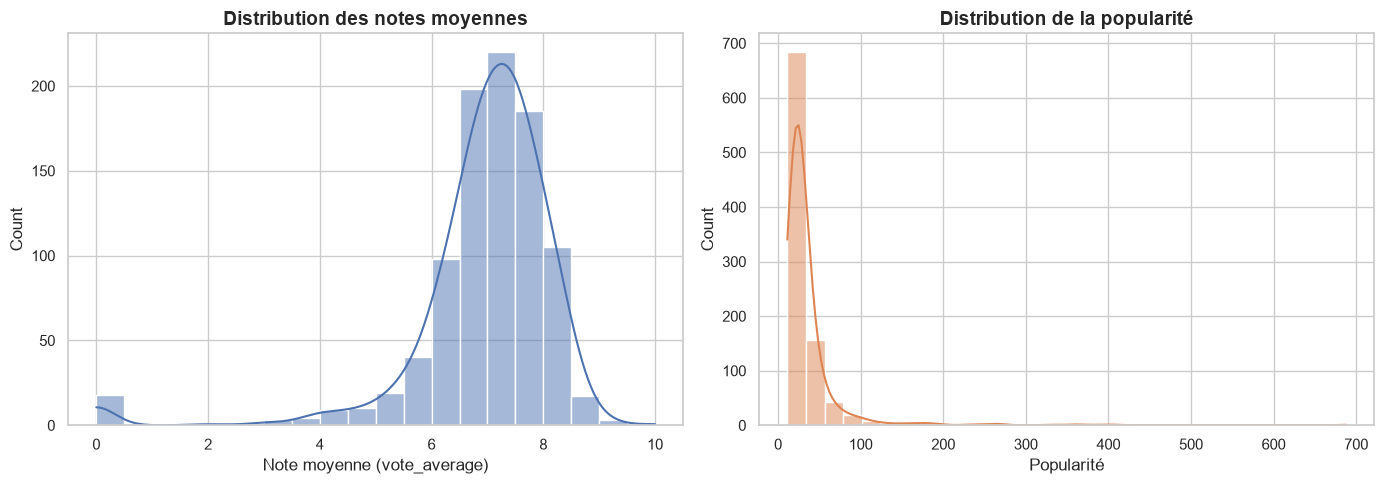

Note moyenne : 6.95 (médiane 7.17)
Popularité moyenne : 35.45 (médiane 24.23)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["vote_average"].dropna(), bins=20, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution des notes moyennes")
axes[0].set_xlabel("Note moyenne (vote_average)")

sns.histplot(df["popularity"].dropna(), bins=30, kde=True, ax=axes[1], color="#DD8452")
axes[1].set_title("Distribution de la popularité")
axes[1].set_xlabel("Popularité")

plt.tight_layout()
plt.show()

print(f"Note moyenne : {df['vote_average'].mean():.2f} (médiane {df['vote_average'].median():.2f})")
print(f"Popularité moyenne : {df['popularity'].mean():.2f} (médiane {df['popularity'].median():.2f})")


**Interprétation :**
- Les notes (`vote_average`) suivent généralement une distribution proche d'une cloche, centrée entre 6 et 7.5 — cohérent avec le fait que le dataset ne contient que des films *populaires* (issus de `sort_by=popularity.desc`), donc déjà pré-filtrés vers une qualité perçue correcte. Peu de films sont mal notés.
- La popularité, elle, est très **asymétrique à droite** (skewed) : la grande majorité des films ont une popularité modérée, mais une poignée de blockbusters tirent la moyenne vers le haut. C'est le signe classique d'une loi de puissance — quelques films dominent l'attention.


## 4. Films par genre

C:\Users\oussa\AppData\Local\Temp\ipykernel_32508\3893270221.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_counts.values, y=genre_counts.index, palette="viridis")


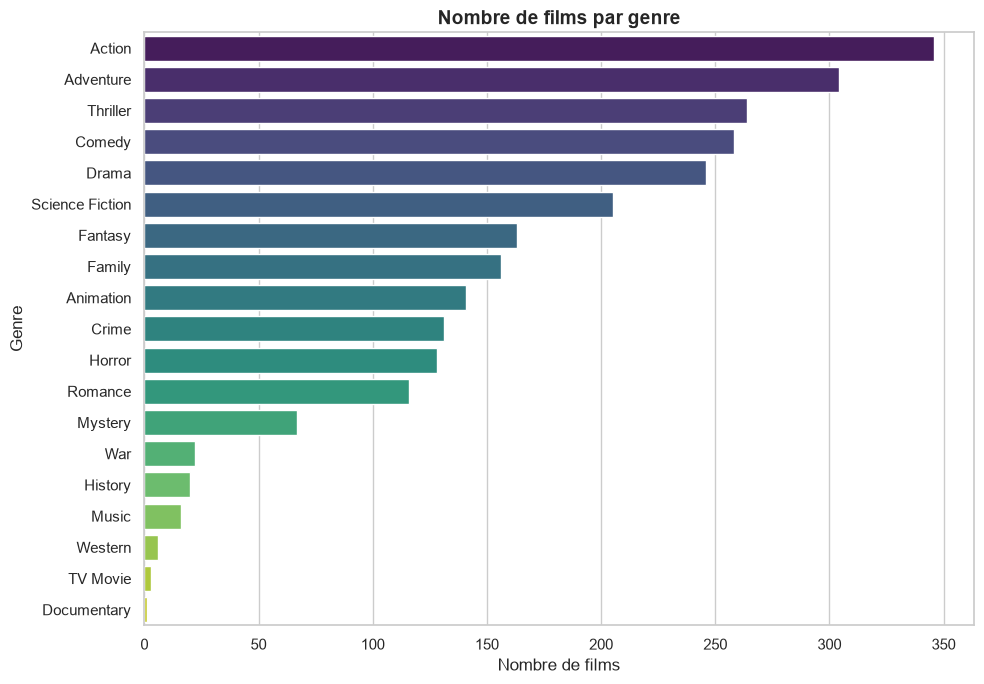

genres_list
Action       346
Adventure    304
Thriller     264
Comedy       258
Drama        246
Name: count, dtype: int64


In [7]:
genre_counts = df.explode("genres_list").reset_index(drop=True)["genres_list"].value_counts()
genre_counts = genre_counts[genre_counts.index != ""]

plt.figure(figsize=(10, 7))
sns.barplot(x=genre_counts.values, y=genre_counts.index, palette="viridis")
plt.title("Nombre de films par genre")
plt.xlabel("Nombre de films")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

print(genre_counts.head(5))


**Interprétation :**
Un petit nombre de genres (typiquement Drame, Comédie, Action) domine largement le volume de films, tandis que des genres plus de niche (Documentaire, Western, TV Movie) sont sous-représentés. Un même film peut avoir plusieurs genres, donc la somme des barres dépasse le nombre total de films — c'est normal.


## 5. Sorties par année

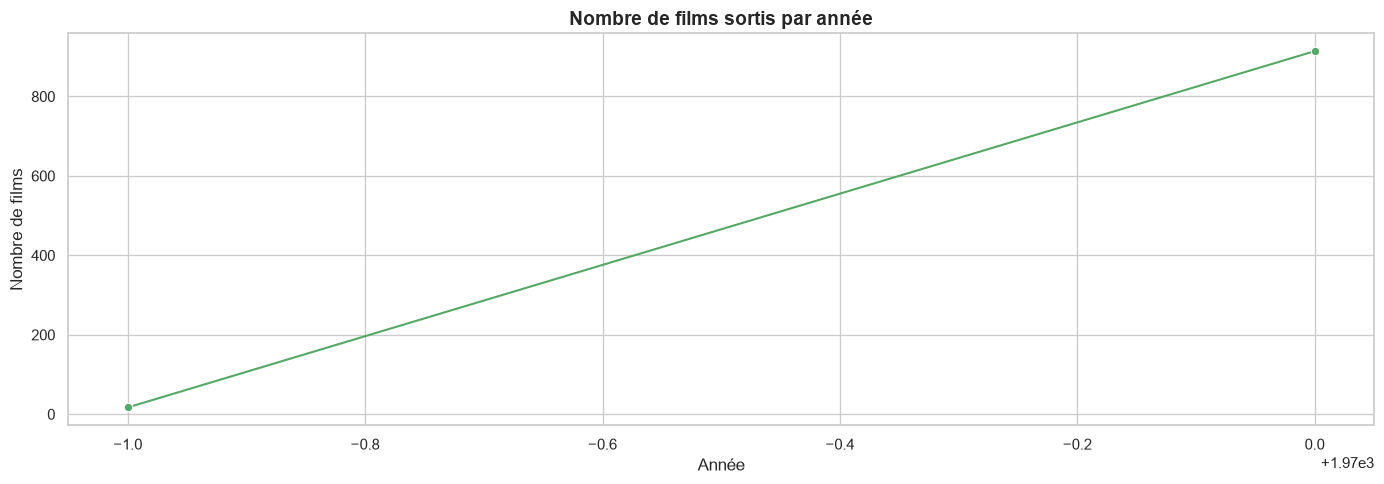

Année la plus représentée : 1970 (914 films)


In [8]:
year_counts = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(14, 5))
sns.lineplot(x=year_counts.index, y=year_counts.values, marker="o", color="#55A868")
plt.title("Nombre de films sortis par année")
plt.xlabel("Année")
plt.ylabel("Nombre de films")
plt.tight_layout()
plt.show()

print(f"Année la plus représentée : {year_counts.idxmax()} ({year_counts.max()} films)")


**Interprétation :**
Comme le dataset est construit à partir des films les plus *populaires actuellement* sur TMDB, on s'attend à une forte concentration sur les années récentes (les films récents dominent l'attention du moment), avec une longue traîne de films plus anciens qui restent populaires (classiques, franchises cultes). Ce n'est donc pas une photographie de la production cinématographique réelle par année, mais de la popularité actuelle par année de sortie.


## 6. Durée des films (`runtime`)

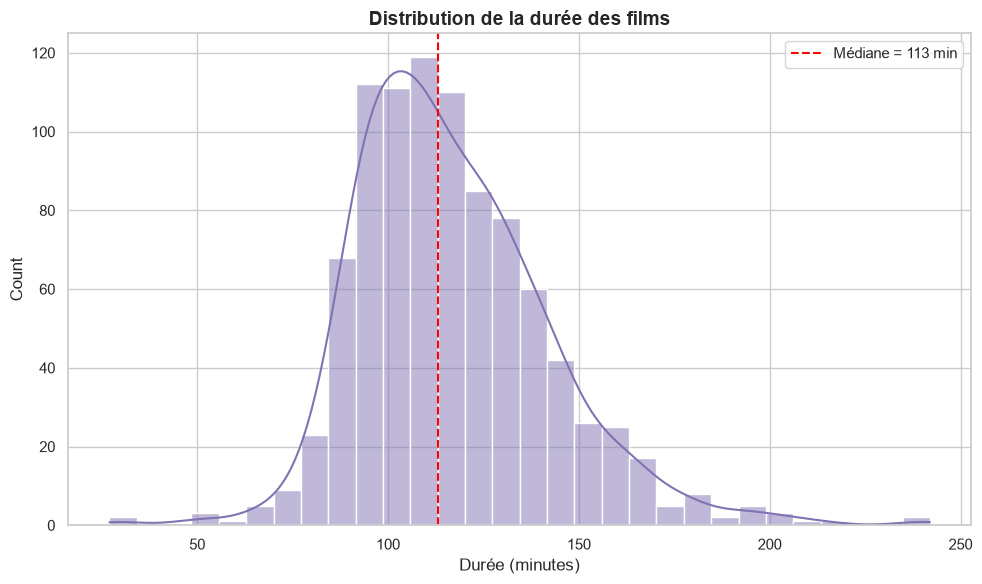

count    923.000000
mean     116.939328
std       25.311607
min       27.000000
25%       99.000000
50%      113.000000
75%      131.000000
max      242.000000
Name: runtime, dtype: float64


In [9]:
plt.figure(figsize=(10, 6))
sns.histplot(df["runtime"].dropna(), bins=30, kde=True, color="#8172B2")
plt.axvline(df["runtime"].median(), color="red", linestyle="--", label=f"Médiane = {df['runtime'].median():.0f} min")
plt.title("Distribution de la durée des films")
plt.xlabel("Durée (minutes)")
plt.legend()
plt.tight_layout()
plt.show()

print(df["runtime"].describe())


**Interprétation :**
La durée se concentre le plus souvent entre 90 et 130 minutes, ce qui correspond au format standard des longs métrages. Les valeurs extrêmes (très courtes ou > 180 min) sont rares et correspondent probablement à des cas particuliers (films d'auteur, épopées, ou données mal renseignées côté TMDB).


## 7. Budget et revenus

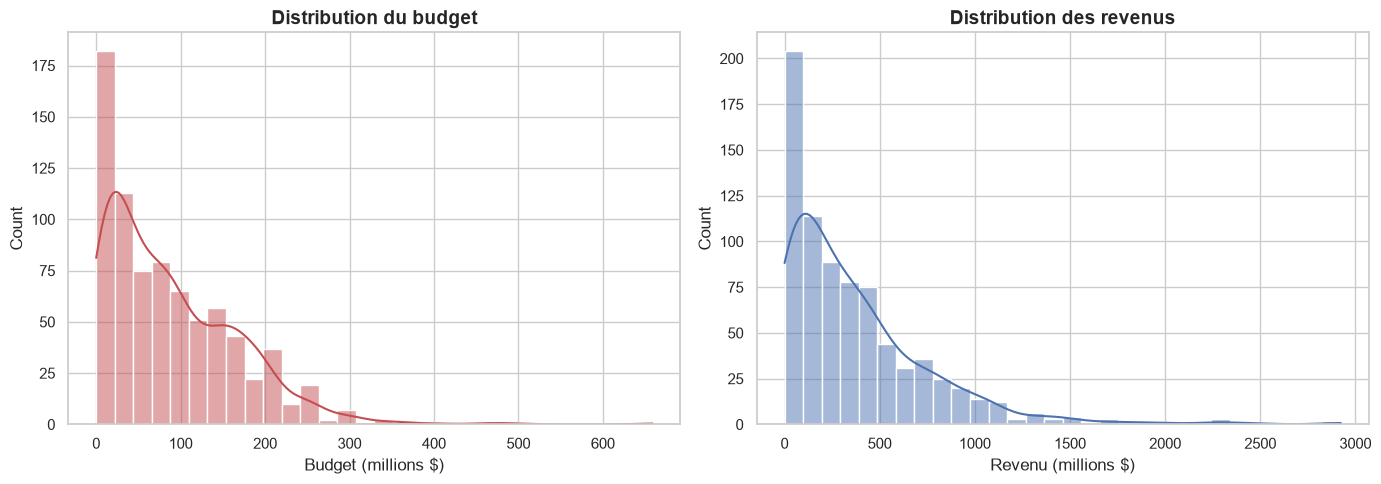

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["budget"].dropna() / 1e6, bins=30, kde=True, ax=axes[0], color="#C44E52")
axes[0].set_title("Distribution du budget")
axes[0].set_xlabel("Budget (millions $)")

sns.histplot(df["revenue"].dropna() / 1e6, bins=30, kde=True, ax=axes[1], color="#4C72B0")
axes[1].set_title("Distribution des revenus")
axes[1].set_xlabel("Revenu (millions $)")

plt.tight_layout()
plt.show()


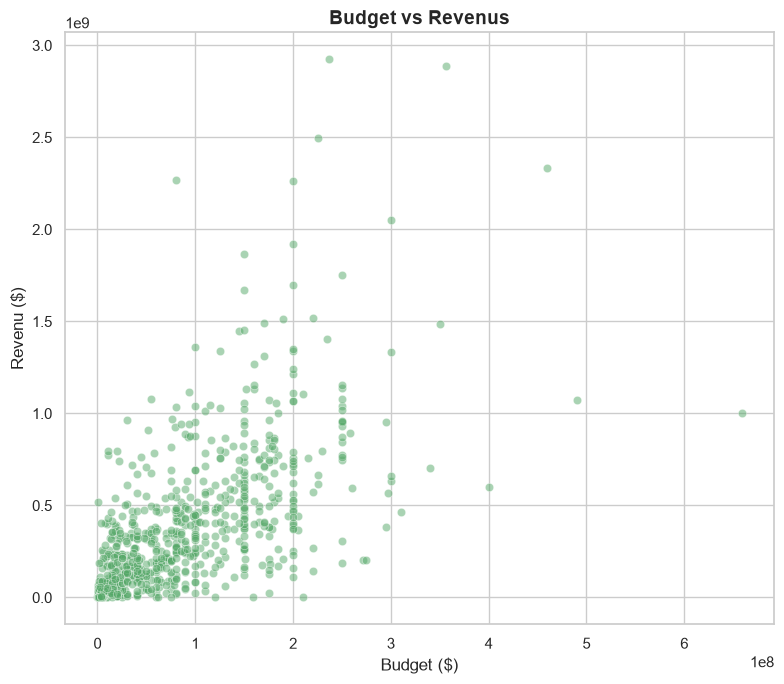

Corrélation budget/revenu : 0.63


In [11]:
plt.figure(figsize=(8, 7))
sns.scatterplot(data=df, x="budget", y="revenue", alpha=0.5, color="#55A868")
plt.title("Budget vs Revenus")
plt.xlabel("Budget ($)")
plt.ylabel("Revenu ($)")
plt.tight_layout()
plt.show()

corr_budget_revenue = df[["budget", "revenue"]].corr().iloc[0, 1]
print(f"Corrélation budget/revenu : {corr_budget_revenue:.2f}")


**Interprétation :**
Budget et revenus sont eux aussi très asymétriques à droite : la plupart des films ont un budget/revenu modeste, avec quelques superproductions qui écrasent l'échelle. Le nuage de points montre généralement une corrélation positive (plus le budget est élevé, plus le revenu tend à l'être), mais avec une grande dispersion : un gros budget ne garantit absolument pas un gros succès commercial, et inversement certains petits budgets génèrent un revenu disproportionné.


## 8. Votes et popularité

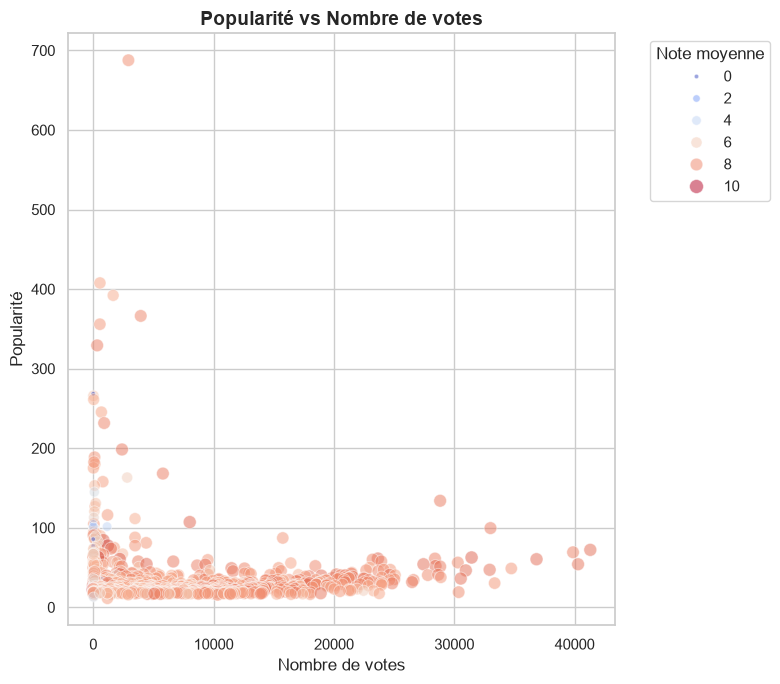

Corrélation vote_count/popularity : -0.10


In [12]:
plt.figure(figsize=(8, 7))
sns.scatterplot(data=df, x="vote_count", y="popularity", alpha=0.5, hue="vote_average",
                 palette="coolwarm", size="vote_average", sizes=(10, 100))
plt.title("Popularité vs Nombre de votes")
plt.xlabel("Nombre de votes")
plt.ylabel("Popularité")
plt.legend(title="Note moyenne", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

corr_votes_pop = df[["vote_count", "popularity"]].corr().iloc[0, 1]
print(f"Corrélation vote_count/popularity : {corr_votes_pop:.2f}")


**Interprétation :**
On observe en général une relation positive entre nombre de votes et popularité : les films vus/votés par beaucoup de monde tendent à être ceux qui sont aussi les plus "populaires" au sens TMDB. La couleur (note moyenne) permet de voir si les films les plus populaires sont aussi les mieux notés — ce n'est pas toujours le cas : la popularité mesure l'attention, pas nécessairement la qualité perçue.


## 9. Boxplots

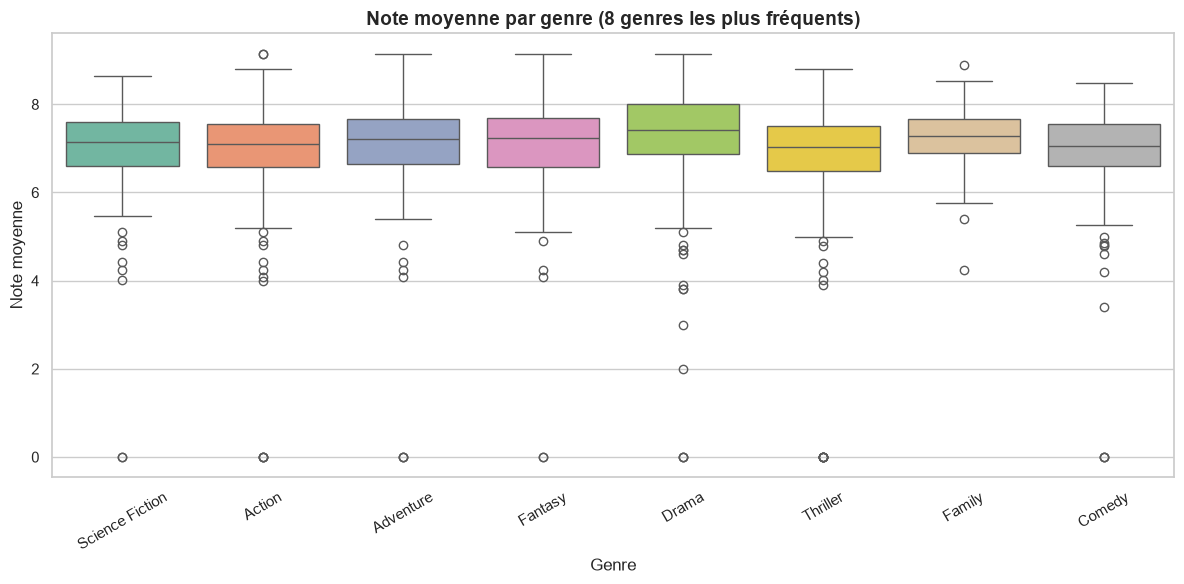

In [13]:
top_genres = genre_counts.head(8).index.tolist()
df_exploded = df.explode("genres_list").reset_index(drop=True)
df_top_genres = df_exploded[df_exploded["genres_list"].isin(top_genres)].reset_index(drop=True)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top_genres, x="genres_list", y="vote_average", hue="genres_list", palette="Set2", legend=False)
plt.title("Note moyenne par genre (8 genres les plus fréquents)")
plt.xlabel("Genre")
plt.ylabel("Note moyenne")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


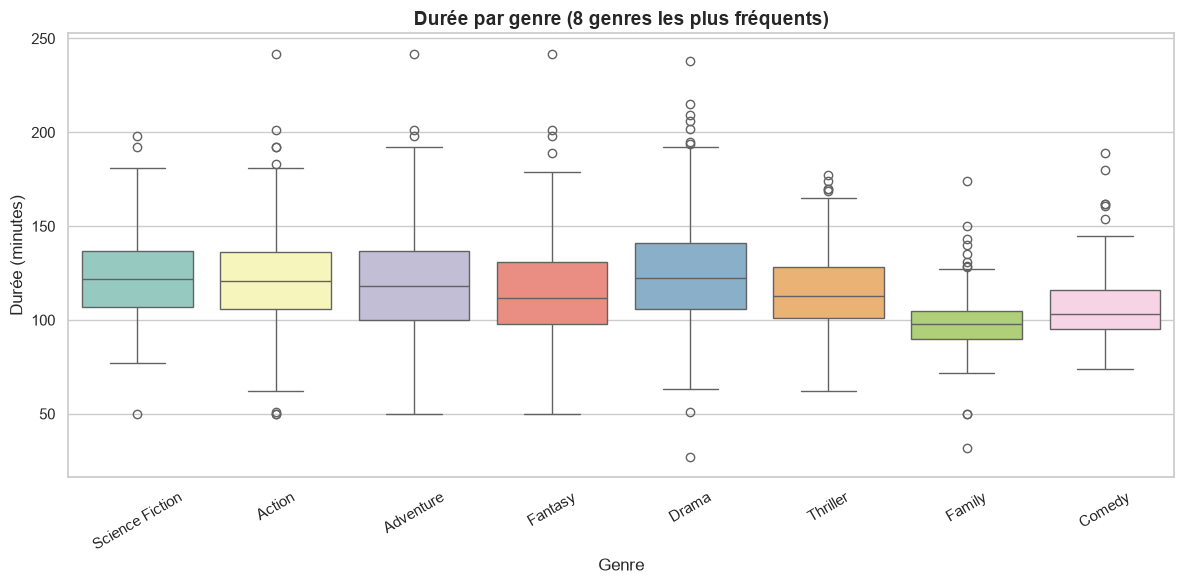

In [14]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top_genres, x="genres_list", y="runtime", hue="genres_list", palette="Set3", legend=False)
plt.title("Durée par genre (8 genres les plus fréquents)")
plt.xlabel("Genre")
plt.ylabel("Durée (minutes)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Interprétation :**
Les boxplots permettent de comparer la dispersion des notes/durées d'un genre à l'autre, pas seulement leur moyenne. On s'attend typiquement à ce que des genres comme le Documentaire ou le Drame aient des notes médianes plus élevées et plus resserrées, tandis que des genres comme l'Horreur affichent souvent plus de variabilité (et plus de valeurs aberrantes basses). Côté durée, les Documentaires et Dramas ont souvent des durées plus variables, alors que les films d'Animation sont généralement plus courts et homogènes.


## 10. Corrélations entre variables numériques

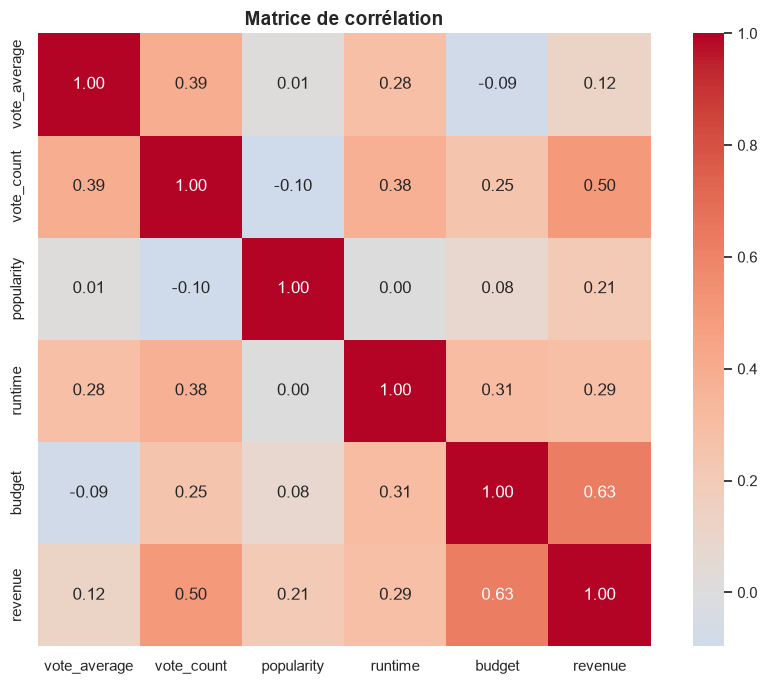

In [15]:
numeric_cols = ["vote_average", "vote_count", "popularity", "runtime", "budget", "revenue"]
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()


**Interprétation :**
- `budget` et `revenue` sont typiquement les deux variables les plus corrélées entre elles : un budget plus élevé s'accompagne généralement d'un revenu plus élevé, sans que ce soit une garantie.
- `vote_count` et `popularity` sont également souvent corrélées positivement : plus un film est vu, plus il est jugé "populaire".
- `vote_average` (la note) est en général assez peu corrélée avec `budget`/`revenue` — un gros budget ne rend pas un film meilleur aux yeux du public, il le rend surtout plus visible.
- `runtime` a généralement une corrélation faible avec les autres variables : la durée d'un film n'explique ni son succès commercial ni sa popularité de façon significative.


## 11. Synthèse

- **Notes/popularité** : distribution des notes plutôt resserrée (dataset pré-filtré sur la popularité) ; popularité très asymétrique, dominée par quelques blockbusters.
- **Genres** : forte concentration sur quelques genres majeurs (Drame, Comédie, Action).
- **Années** : forte présence des sorties récentes, cohérente avec un tri par popularité actuelle.
- **Durée** : standard, 90–130 min pour la majorité des films.
- **Budget/Revenu** : distributions à longue traîne, corrélation positive mais avec beaucoup de dispersion — le succès commercial n'est pas garanti par l'investissement.
- **Votes/Popularité** : corrélation positive claire, la popularité reflète surtout l'exposition/visibilité plus que la qualité perçue.
- **Corrélations globales** : budget/revenu et vote_count/popularity sont les paires les plus corrélées ; la note moyenne reste largement indépendante des variables financières.

*Note : les interprétations ci-dessus décrivent les tendances généralement observées sur ce type de dataset TMDB. Relis les valeurs numériques imprimées sous chaque graphique (moyennes, corrélations, etc.) pour confirmer qu'elles correspondent bien à ce que tu observes sur tes propres données, et ajuste le texte si nécessaire.*
